![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Sesión 1 · Versión resuelta · referencia</div><div style="font-size:22px;font-weight:700;margin-top:4px">L1.3 · Evaluar sin engañarse</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Objetivo** | Medir bien: matriz de confusión y curva ROC, sobreajuste y subajuste, curvas de aprendizaje, validación cruzada frente a leave-one-out, y fuga de datos. |
| **Duración** | ≈ 75 min |
| **Teoría** | Manual M1 §9–§11 · Animaciones A1.11 a A1.17 |
| **Datos icónicos** | **MNIST** (el detector «¿es un 5?») · **Iris** (validación cruzada frente a leave-one-out) |
| **Escala realista** | **Titanic** (891 pasajeros, datos tabulares con faltantes y una fuga escondida) |

**Partes:** 1 · matriz de confusión y ROC → 2 · sobreajuste con la profundidad del árbol → 3 · curvas de aprendizaje → 4 · K-fold frente a leave-one-out → 5 · Titanic: pipeline sin fuga.

## 0 · Configuración

In [1]:
import os
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 2026
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=list(UNIBE.values())), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
CACHE = os.path.expanduser("~/.cache/ml-unibe")


def descargar(url, nombre):
    os.makedirs(CACHE, exist_ok=True)
    ruta = os.path.join(CACHE, nombre)
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(url, ruta)
    return ruta


d = np.load(descargar("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", "mnist.npz"))
rng = np.random.default_rng(SEED)
i_tr, i_te = rng.choice(60_000, 10_000, replace=False), rng.choice(10_000, 2_000, replace=False)
X_tr, y_tr = d["x_train"][i_tr].reshape(-1, 784) / 255.0, d["y_train"][i_tr]
X_te, y_te = d["x_test"][i_te].reshape(-1, 784) / 255.0, d["y_test"][i_te]
print(f"scikit-learn {sklearn.__version__} · MNIST: {X_tr.shape[0]} de entrenamiento, {X_te.shape[0]} de prueba")

scikit-learn 1.9.1 · MNIST: 10000 de entrenamiento, 2000 de prueba


## Parte 1 · Matriz de confusión y curva ROC

**La matriz de 10 × 10.** Entrenamos una regresión logística multinomial y miramos qué dígitos confunde.

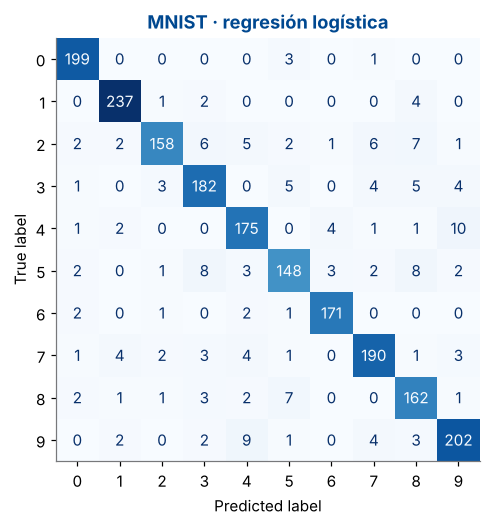

              precision    recall  f1-score   support

           0      0.948     0.980     0.964       203
           1      0.956     0.971     0.963       244
           2      0.946     0.832     0.885       190
           3      0.883     0.892     0.888       204
           4      0.875     0.902     0.888       194
           5      0.881     0.836     0.858       177
           6      0.955     0.966     0.961       177
           7      0.913     0.909     0.911       209
           8      0.848     0.905     0.876       179
           9      0.906     0.906     0.906       223

    accuracy                          0.912      2000
   macro avg      0.911     0.910     0.910      2000
weighted avg      0.913     0.912     0.912      2000



In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

modelo = LogisticRegression(max_iter=300, C=0.1).fit(X_tr, y_tr)
fig, ax = plt.subplots(figsize=(5.4, 5))
ConfusionMatrixDisplay.from_estimator(modelo, X_te, y_te, cmap="Blues", colorbar=False, ax=ax)
ax.set_title("MNIST · regresión logística"); ax.grid(False); plt.show()
print(classification_report(y_te, modelo.predict(X_te), digits=3))

**Tu turno.** Encuentra la confusión más frecuente: el par (real, predicho) con más errores fuera de la diagonal.

In [3]:
from sklearn.metrics import confusion_matrix

M = confusion_matrix(y_te, modelo.predict(X_te))
# TODO: anula la diagonal de una copia de M y encuentra la celda máxima (np.unravel_index + argmax).
F = M.copy(); np.fill_diagonal(F, 0)
real, pred = np.unravel_index(np.argmax(F), F.shape)
print(f"La confusión más frecuente: {real} confundido con {pred} ({F[real, pred]} veces)")
assert F[real, pred] == F.max() and real != pred

La confusión más frecuente: 4 confundido con 9 (10 veces)


**El detector «¿es un 5?».** Un problema binario icónico (Géron, cap. 3). Primero, el clasificador más tonto: decir siempre «no es un 5».

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve

y5_tr, y5_te = (y_tr == 5).astype(int), (y_te == 5).astype(int)
nunca = DummyClassifier(strategy="most_frequent").fit(X_tr, y5_tr)
print(f"«Nunca es un 5»: exactitud = {nunca.score(X_te, y5_te):.3f} · recall = {recall_score(y5_te, nunca.predict(X_te)):.3f}")

«Nunca es un 5»: exactitud = 0.911 · recall = 0.000


Más de 90 % de exactitud sin aprender nada: solo ≈ 9 % de las imágenes son cincos. Por eso miramos precisión, recall y la curva ROC.

umbral 0.5: precisión = 0.905 · recall = 0.751
umbral 0.2: precisión = 0.712 · recall = 0.864
umbral 0.8: precisión = 0.980 · recall = 0.548


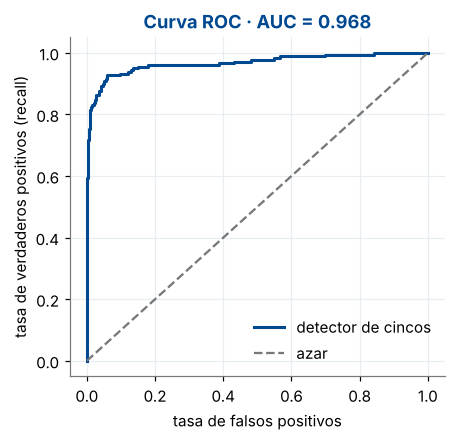

In [5]:
det5 = LogisticRegression(max_iter=300, C=0.1).fit(X_tr, y5_tr)
p5 = det5.predict_proba(X_te)[:, 1]
# TODO: calcula el AUC-ROC del detector con roc_auc_score.
auc5 = roc_auc_score(y5_te, p5)
for t in (0.5, 0.2, 0.8):
    pr = (p5 >= t).astype(int)
    print(f"umbral {t}: precisión = {precision_score(y5_te, pr):.3f} · recall = {recall_score(y5_te, pr):.3f}")
fig, ax = plt.subplots(figsize=(4.4, 4))
fpr, tpr, _ = roc_curve(y5_te, p5)   # calculamos la curva a mano: funciona con cualquier versión de scikit-learn
ax.plot(fpr, tpr, color=UNIBE["azul"], lw=2, label="detector de cincos")
ax.set(xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos (recall)")
ax.plot([0, 1], [0, 1], ls="--", color=UNIBE["gris"], label="azar"); ax.legend(); ax.set_title(f"Curva ROC · AUC = {auc5:.3f}"); plt.show()
assert auc5 > 0.95

## Parte 2 · Sobreajuste: la profundidad del árbol

Entrenamos árboles cada vez más profundos y medimos la exactitud en entrenamiento y en **validación** (una parte del entrenamiento que el árbol no ve). La prueba no se toca.

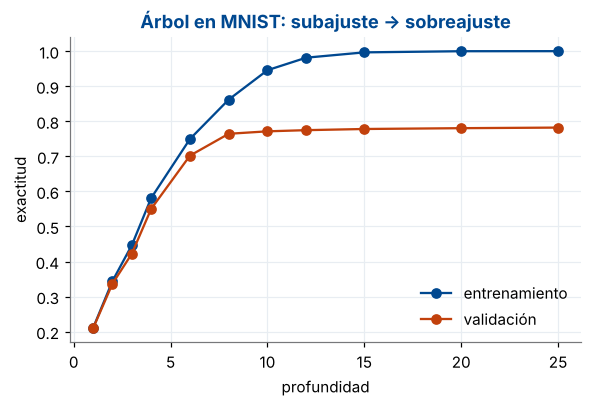

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

Xa, Xv, ya, yv = train_test_split(X_tr, y_tr, test_size=0.3, random_state=SEED, stratify=y_tr)
profundidades = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 25]
curva = []
for p in profundidades:
    t = DecisionTreeClassifier(max_depth=p, random_state=SEED).fit(Xa, ya)
    curva.append((p, t.score(Xa, ya), t.score(Xv, yv)))
curva = pd.DataFrame(curva, columns=["profundidad", "entrenamiento", "validación"])
ax = curva.plot(x="profundidad", y=["entrenamiento", "validación"], marker="o", figsize=(6, 3.6))
ax.set(ylabel="exactitud", title="Árbol en MNIST: subajuste → sobreajuste"); plt.show()

**Tu turno.** Pasada cierta profundidad, la validación se estanca mientras el entrenamiento sigue subiendo: la brecha crece y el árbol solo memoriza. Aplica la **regla del modelo más simple**: elige la profundidad más pequeña cuya validación esté a menos de 0.01 de la mejor.

In [7]:
# TODO: obtén la primera fila de curva cuya validación sea >= (máximo de validación − 0.01).
umbral = curva["validación"].max() - 0.01
mejor = curva[curva["validación"] >= umbral].iloc[0]
ultima = curva.iloc[-1]
print(f"Profundidad elegida = {int(mejor['profundidad'])} · validación = {mejor['validación']:.3f} · brecha = {mejor['entrenamiento'] - mejor['validación']:.3f}")
print(f"Profundidad {int(ultima['profundidad'])}: validación = {ultima['validación']:.3f} · brecha = {ultima['entrenamiento'] - ultima['validación']:.3f}  ← casi igual en validación, mucha más memoria")
assert curva["entrenamiento"].iloc[-1] > 0.99, "Un árbol muy profundo memoriza el entrenamiento."

Profundidad elegida = 12 · validación = 0.775 · brecha = 0.207
Profundidad 25: validación = 0.782 · brecha = 0.218  ← casi igual en validación, mucha más memoria


## Parte 3 · Curvas de aprendizaje: ¿más datos o más modelo?

Con `learning_curve` entrenamos con 10 %, 25 %… 100 % de los datos y medimos con validación cruzada. Comparamos un modelo simple (Naive Bayes) con uno flexible (k vecinos).

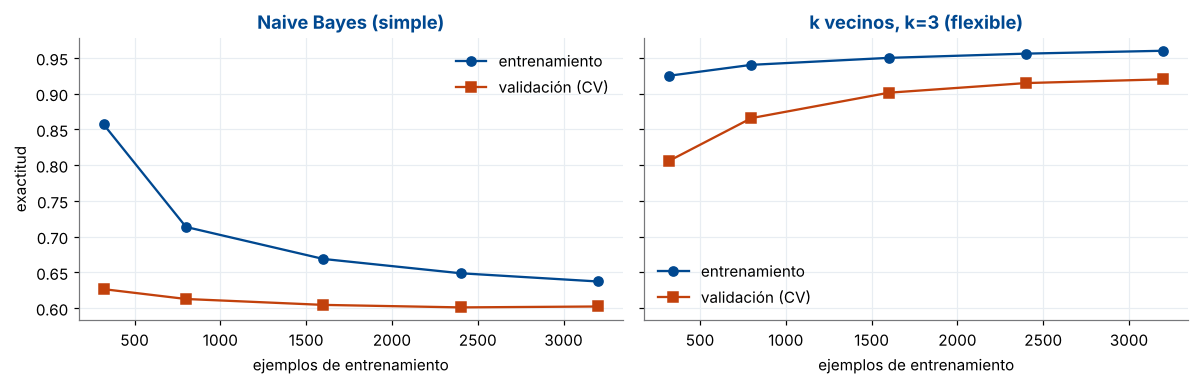

In [8]:
from sklearn.model_selection import learning_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (nombre, m) in zip(axs, [("Naive Bayes (simple)", GaussianNB()), ("k vecinos, k=3 (flexible)", KNeighborsClassifier(3))]):
    n, tr, va = learning_curve(m, X_tr[:4000], y_tr[:4000], train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], cv=5)
    ax.plot(n, tr.mean(1), "o-", label="entrenamiento"); ax.plot(n, va.mean(1), "s-", label="validación (CV)")
    ax.set(title=nombre, xlabel="ejemplos de entrenamiento"); ax.legend()
axs[0].set_ylabel("exactitud"); plt.tight_layout(); plt.show()

Lectura: en Naive Bayes las curvas quedan juntas y bajas (**sesgo**: más datos no lo salvan; hace falta otro modelo). En k vecinos la validación sigue subiendo con más datos (más datos **sí** ayudan).

## Parte 4 · Validación cruzada K-fold frente a leave-one-out

Con **Iris** (150 flores) leave-one-out son solo 150 entrenamientos. Comparamos la estimación de exactitud de k vecinos con 5-fold barajado de 20 formas distintas y con LOO.

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_score

Xi, yi = load_iris(return_X_y=True)
knn5 = KNeighborsClassifier(n_neighbors=5)
k5 = [cross_val_score(knn5, Xi, yi, cv=KFold(5, shuffle=True, random_state=s)).mean() for s in range(20)]
print(f"5-fold con 20 barajados: de {min(k5):.3f} a {max(k5):.3f} (media {np.mean(k5):.3f})")

# TODO: calcula la exactitud LOO con cross_val_score(..., cv=LeaveOneOut()) y cuenta cuántos modelos se entrenaron.
loo = cross_val_score(knn5, Xi, yi, cv=LeaveOneOut())
print(f"Leave-one-out: exactitud = {loo.mean():.3f} con {len(loo)} modelos entrenados (uno por flor)")
assert len(loo) == 150

5-fold con 20 barajados: de 0.940 a 0.973 (media 0.960)


Leave-one-out: exactitud = 0.967 con 150 modelos entrenados (uno por flor)


LOO da **un solo número**: no depende del barajado. 5-fold da un valor distinto según cómo se barajen los datos, pero cuesta 5 entrenamientos en vez de 150. Con MNIST (60 000 imágenes), LOO serían 60 000 entrenamientos: impracticable.

## Parte 5 · Escala realista: Titanic sin fuga

891 pasajeros del Titanic con clase, sexo, edad, tarifa y puerto de embarque, y si **sobrevivieron**. Es un problema tabular de verdad: hay faltantes (edad, cubierta) y variables categóricas. Usamos la versión publicada por el proyecto seaborn.

In [10]:
URL_TIT = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
tit = pd.read_csv(descargar(URL_TIT, "titanic.csv"))
print(tit.shape, "· sobrevivió:", f"{tit['survived'].mean():.1%}")
print("Faltantes por columna:\n", tit.isna().sum()[tit.isna().sum() > 0])
tit.head()

(891, 15) · sobrevivió: 38.4%
Faltantes por columna:
 age            177
embarked         2
deck           688
embark_town      2
dtype: int64


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Una fuga escondida.** Esta versión trae una columna `alive` («yes»/«no»). Entrenemos un árbol con todas las columnas, como haría alguien con prisa:

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

y_t = tit["survived"]
todas = tit.drop(columns=["survived"])
cat_all = todas.select_dtypes(exclude="number").columns.tolist()
num_all = todas.select_dtypes(include="number").columns.tolist()
prep_all = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_all),
                              ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_all)])
con_fuga = Pipeline([("prep", prep_all), ("arbol", DecisionTreeClassifier(max_depth=3, random_state=SEED))])
print(f"Con todas las columnas: exactitud CV = {cross_val_score(con_fuga, todas, y_t, cv=5).mean():.3f}  ← sospechoso")

Con todas las columnas: exactitud CV = 1.000  ← sospechoso


**Tu turno.** ¿Qué columna es la fuga? Identifícala comparándola con `survived` y arma un pipeline **sin fuga** con solo `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare` y `embarked` (imputación y escalado dentro del pipeline) y una regresión logística.

In [12]:
print(pd.crosstab(tit["alive"], tit["survived"]))
num, cat = ["age", "sibsp", "parch", "fare"], ["pclass", "sex", "embarked"]
# TODO: arma el ColumnTransformer (num: imputar mediana + escalar; cat: imputar moda + one-hot) y el Pipeline con LogisticRegression.
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
sin_fuga = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])
acc_sin = cross_val_score(sin_fuga, tit[num + cat], y_t, cv=5)
print(f"Sin fuga: exactitud CV = {acc_sin.mean():.3f} ± {acc_sin.std():.3f}")
assert 0.72 < acc_sin.mean() < 0.9, "Un modelo honesto en Titanic ronda el 80 %."

survived    0    1
alive             
no        549    0
yes         0  342
Sin fuga: exactitud CV = 0.790 ± 0.022


**Y el árbol que «redescubre» la regla del naufragio.** Un árbol de profundidad 2 sin fuga, leído como reglas:

In [13]:
from sklearn.tree import export_text

arbol_t = Pipeline([("prep", prep), ("arbol", DecisionTreeClassifier(max_depth=2, random_state=SEED))]).fit(tit[num + cat], y_t)
nombres = arbol_t.named_steps["prep"].get_feature_names_out()
print(export_text(arbol_t.named_steps["arbol"], feature_names=list(nombres)))

|--- cat__sex_female <= 0.50
|   |--- num__age <= -1.76
|   |   |--- class: 1
|   |--- num__age >  -1.76
|   |   |--- class: 0
|--- cat__sex_female >  0.50
|   |--- cat__pclass_3 <= 0.50
|   |   |--- class: 1
|   |--- cat__pclass_3 >  0.50
|   |   |--- class: 0



## Reflexión

1. Tu detector de cincos tiene 93 % de exactitud. ¿Qué otra cifra pedirías antes de creerle?
2. ¿Desde qué profundidad el árbol ya no mejora en validación y solo memoriza? ¿Cómo lo reconociste?
3. ¿Por qué la columna `alive` es una fuga? ¿Existiría ese dato al momento de predecir?

> **Respuesta de referencia**

1. El recall (y la precisión) del detector, y su comparación con el baseline «nunca es un 5», que ya tiene más de 90 % de exactitud. La curva ROC y el AUC resumen el desempeño en todos los umbrales.
2. Desde la profundidad en la que la validación se estanca (≈ 10 a 12 en esta muestra) mientras el entrenamiento sigue acercándose a 1: la brecha crece. Ante un empate práctico se elige el árbol más simple, que generaliza igual y es más fácil de leer.
3. `alive` es la misma respuesta escrita de otra forma: «yes» si sobrevivió. Al momento de predecir (al zarpar) no existe. Con ella el modelo «acierta» casi siempre sin aprender nada útil.

## Desafío opcional con IA agéntica · Caza de fugas en código generado

**Objetivo.** Pedir a un asistente de IA un modelo para Titanic y auditar su código en busca de fugas de datos y de decisiones tomadas con la prueba.

**Prompt inicial.** Úsalo en la herramienta que prefieras (Claude Code, Codex, Gemini en Colab, ChatGPT…), con este notebook resuelto como contexto. Pide primero un plan y revisa cada paso antes de aprobarlo.

```text
Escribe en Python un notebook que prediga la supervivencia en el Titanic con el CSV de seaborn (https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv), compare una regresión logística, un árbol de decisión y k vecinos, y elija el umbral de decisión. Muéstrame primero el plan. Al final, haz una lista de cada paso que aprenda de los datos (imputación, escalado, codificación, selección del umbral) e indica con qué subconjunto se ajusta cada uno.
```

**Cómo verificar el resultado**

- Ninguna columna derivada de la respuesta (alive) entra al modelo.
- Imputación, escalado y one-hot están dentro de un Pipeline evaluado con validación cruzada.
- El umbral se elige con validación, no con la prueba; si el código generado lo hacía mal, documentas el error y cómo lo corregiste.

**Declara el uso de IA** (como pide el sílabo): herramienta, prompts relevantes, qué verificaste tú y qué corregiste. El desafío es opcional y no se califica; lo que cuenta es que puedas explicar cada decisión.